# HS → RGB Alignment Demo (camiira)

In this notebook, I show an end-to-end workflow for aligning hyperspectral (HS) images to RGB images using manual anchor points, then applying the learned transform to new point sets for downstream matching.


In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from camiira.align import (
    Aligner,
    find_affine,
    get_query2target_func,
    get_query2target_func_rev,
)
from camiira.utils import _get_time_points

## 1. Load Demo Data and Pick One HS/RGB Pair
We will list files under `/mnt/c/aws_data/data/camii/202401_darpa_arcadia_arl_boneyard/` and select one HS/RGB pair using the same time-point pairing logic as the project notebooks.

In [2]:
base_dir = Path("/mnt/c/aws_data/data/camii/202401_darpa_arcadia_arl_boneyard")

# Mirror the pairing logic used in project notebooks
png_rgb_dir = base_dir / "rgb" / "white_rgb"
png_hsi_dir = base_dir / "hyperspectral_pca"

time_point_rgb = "max"
time_point_hsi = 5

plates_rgb = dict(zip(*_get_time_points(str(png_rgb_dir), time=time_point_rgb)))
plates_hsi = dict(
    zip(*_get_time_points(str(png_hsi_dir), time=time_point_hsi, missing_tp="silence"))
)

plates = sorted(set(plates_hsi).intersection(set(plates_rgb)))
print(f"Plates with both RGB and HSI: {len(plates)}")

# Hard-coded demo plate (confirmed available in this dataset)
plate = "ABYPS158"
if plate not in plates:
    raise ValueError(f"Plate {plate} not found in paired RGB/HSI data.")

rgb_path = Path(plates_rgb[plate])
hsi_path = Path(plates_hsi[plate])

plate, rgb_path, hsi_path

Plates with both RGB and HSI: 9


('ABYPS158',
 PosixPath('/mnt/c/aws_data/data/camii/202401_darpa_arcadia_arl_boneyard/rgb/white_rgb/ABYPS158_d5.png'),
 PosixPath('/mnt/c/aws_data/data/camii/202401_darpa_arcadia_arl_boneyard/hyperspectral_pca/ABYPS158_d5_pc3.png'))

## 2. Manually Annotate Anchor Points and Export CSV
Use an external tool (e.g., makesense.ai, CVAT, labelImg) to annotate **anchor/key points** on both the RGB image and the HS image.

In this project, anchors are stored as CSV files in an `align_anchor/` folder (one for RGB and one for HSI), with columns:

`class, x, y, plate, width, height`

We will read these CSVs and convert them to the `center_x`, `center_y` format expected by `Aligner`.

In [4]:
align_anchor_rgb = pd.read_csv(
    base_dir / "align_anchor" / "rgb.csv",
    names=["class", "x", "y", "plate", "width", "height"],
)
align_anchor_hsi = pd.read_csv(
    base_dir / "align_anchor" / "hsi.csv",
    names=["class", "x", "y", "plate", "width", "height"],
)

rgb_anchor_df = align_anchor_rgb.query(
    "plate == @os.path.basename(@rgb_path)"
)[["x", "y"]].rename(columns={"x": "center_x", "y": "center_y"})

hsi_anchor_df = align_anchor_hsi.query(
    "plate == @os.path.basename(@hsi_path)"
)[["x", "y"]].rename(columns={"x": "center_x", "y": "center_y"})

rgb_anchor_df, hsi_anchor_df

(    center_x  center_y
 0       1210       694
 1       1176       822
 2       1260       848
 3       1354       635
 4       1071       957
 5        237      1124
 6       1646      1048
 7       1661      1085
 8       1683      1100
 9       1627      1146
 10       330       288
 11       236       344
 12       293       335
 13       246       306
 14       223       257
 15      1158       208
 16      1091       171
 17      1606       290
 18      1607       354,
     center_x  center_y
 19       454       453
 20       478       549
 21       411       566
 22       564       650
 23       333       412
 24      1149       149
 25      1179       189
 26      1223       194
 27      1214       162
 28      1230       122
 29        72       763
 30       101       721
 31        90       750
 32       119       797
 33      1228       768
 34       130       158
 35       130       203
 36       488        92
 37       542        64)

## 3. Run Alignment with CAMIIRA Utilities (Key Args + Math)
CAMIIRA uses an affine transform to map HS points into RGB space. Conceptually:

$$
\mathbf{x}' = A\mathbf{x} + \mathbf{b}
$$

In CAMIIRA’s parameterization, this is a **rotation + anisotropic scaling + translation** with parameters $(a, b, t_x, t_y, s_x, s_y)$.

**Key arguments to know:**
- `query` = "hsi" and `target` = "rgb" (HS → RGB)
- `hparams` = optimizer settings (learning rate, epochs, penalties)
- `flip` = whether horizontal/vertical flips are allowed
- `params_init` = warm start parameters if you already have a good initialization
- `mean_q/std_q`, `mean_t/std_t` = normalization stats (optional; computed automatically if images are provided)

In [5]:
# Build aligner from one HS/RGB pair
aligner = Aligner(
    plate_barcode=plate,
    rgb_png_path=str(rgb_path),
    hsi_png_path=str(hsi_path),
)

# Load anchor points into the aligner
# Ensure columns are [center_x, center_y]
aligner._meta_rgb = rgb_anchor_df[["center_x", "center_y"]]
aligner._meta_hsi = hsi_anchor_df[["center_x", "center_y"]]

# Fit HS → RGB alignment (hyperparameters aligned with project notebooks)
aligner.fit(
    query="hsi",
    target="rgb",
    hparams={
        "lr": 0.005,
        "max_epochs": 10000,
        "patience": 100,
        "beta_d": 0.1,
        "beta_c": 5,
        "beta_t": 0.0,
        "beta_s": 0.1,
    },
    flip=True,
)

# Create mapping structures (mutual nearest neighbors, filtered mappings)
aligner.transform(query="hsi", target="rgb")

# Inspect learned transform parameters
params = aligner._func_rgb_hsi2rgb_params
stats = aligner._func_rgb_hsi2rgb_stats
flip = aligner._func_rgb_hsi2rgb_flip

params, stats, flip

Optimized Parameters at Epoch 168:

Flip horizontally; Rotate around origin clockwise: 0.485°; Scale along axes: (0.849, 0.894); Translate: (-0.027, 
0.033)

(array([ 1.1039367 ,  0.00934215, -0.02660586,  0.03265576,  0.84922594,
         0.89397764], dtype=float32),
 [array([655. , 429.5], dtype=float32),
  array([436.66666, 286.33334], dtype=float32),
  array([969., 648.], dtype=float32),
  array([646., 432.], dtype=float32)],
 (True, False))

### 3.1 Under-the-hood transform functions (module-level)
CAMIIRA builds the transform with module functions in [src/camiira/align.py](src/camiira/align.py):
- `find_affine()` optimizes the affine parameters and returns params + stats + flip
- `get_query2target_func()` returns a callable for **query → target**
- `get_query2target_func_rev()` returns a callable for **target → query**
- `affine_transform()` / `affine_transform_rev()` apply the affine mapping directly

Below is the equivalent module-level workflow to what `Aligner.fit()` creates internally.

In [6]:
# Prepare query/target coordinates
coords_hsi = hsi_anchor_df[["center_x", "center_y"]].to_numpy()
coords_rgb = rgb_anchor_df[["center_x", "center_y"]].to_numpy()

# Module-level affine fitting (same hyperparams as above)
params, mean_q, std_q, mean_t, std_t, flip, hparams = find_affine(
    coords_hsi,
    coords_rgb,
    hparams={
        "lr": 0.005,
        "max_epochs": 10000,
        "patience": 100,
        "beta_d": 0.1,
        "beta_c": 5,
        "beta_t": 0.0,
        "beta_s": 0.1,
    },
    flip=True,
)

# Build forward (HS → RGB) and inverse (RGB → HS) callables
hsi_to_rgb_func = get_query2target_func(
    *params,
    mean_q=mean_q,
    std_q=std_q,
    mean_t=mean_t,
    std_t=std_t,
    flip=flip,
)

rgb_to_hsi_func = get_query2target_func_rev(
    *params,
    mean_q=mean_q,
    std_q=std_q,
    mean_t=mean_t,
    std_t=std_t,
    flip=flip,
)

# Example: apply to the first HS anchor point
sample_hsi = coords_hsi[:1]
sample_rgb = hsi_to_rgb_func(sample_hsi)

sample_hsi, sample_rgb

Optimized Parameters at Epoch 111:

Flip horizontally; Rotate around origin clockwise: 0.462°; Scale along axes: (0.999, 1.007); Translate: (0.001, 
0.003)

(array([[454, 453]]), array([[1204.7828,  692.3722]], dtype=float32))

## 4. Inspect Alignment Outputs and Visual Overlays
We overlay transformed HS anchors onto the RGB image for manual inspection.

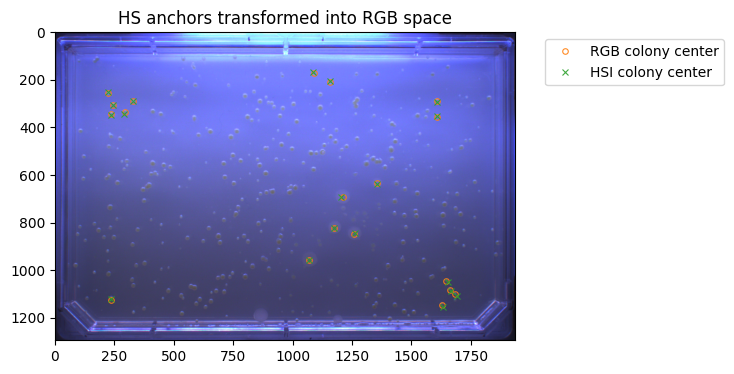

In [7]:
# Plot alignment using built-in helper
fig, ax = plt.subplots(figsize=(6, 4))
aligner.plot("rgb", ["hsi"], ax=ax, plot_bg=True)
ax.set_title("HS anchors transformed into RGB space")
plt.show()

# Optionally save diagnose image
# diagnose_dir = base_dir / "align_diagnose_demo"
# diagnose_dir.mkdir(parents=True, exist_ok=True)
# fig.savefig(diagnose_dir / "demo_alignment.png", dpi=300, bbox_inches="tight")

## 5. Apply Transform to New Point Sets.
Now we apply the learned transformation to **real colony centers** (not anchor points). The typical workflow is:
1. Train alignment using manually annotated anchors
2. Load detected colony centers from `*_metadata.csv` files
3. Transform HS colony centers → RGB space
4. Find matching pairs using mutual nearest neighbors + graph cleanup

The pairing uses `aligner.transform()` which applies:
- **Mutual nearest neighbors**: finds candidate pairs
- **Graph cleanup**: removes ambiguous query nodes (HS colonies with `out_degree > 1`)
- Result: cleaner mapping (not strictly one-to-one, but each query maps to ≤1 target)

The `Aligner` stores:
- `_coords_hsi2rgb` (HS points transformed into RGB space)
- `_map_rgb_hsi2rgb` (raw mutual nearest neighbor mapping)

- `_map_rgb_hsi2rgb_clean` (filtered mapping after cleanup)- `_bad_rgb_hsi2rgb_idx` (indices of removed query points)

In [9]:
# Load RGB colony centers (detected from RGB images)
rgb_colony_meta_path = base_dir / "colony_detection_rgb" / "max" / f"{plate}_metadata.csv"
rgb_colony_df = pd.read_csv(rgb_colony_meta_path)
rgb_colony_centers = rgb_colony_df[["center_x", "center_y"]].to_numpy()

# Load HS colony centers (detected from HS images)
hsi_colony_meta_path = base_dir / "colony_detection_hsi" / f"d{time_point_hsi}" / f"{plate}_metadata.csv"
hsi_colony_df = pd.read_csv(hsi_colony_meta_path)
hsi_colony_centers = hsi_colony_df[["center_x", "center_y"]].to_numpy()

print(f"RGB colonies: {len(rgb_colony_centers)}, HS colonies: {len(hsi_colony_centers)}")

RGB colonies: 345, HS colonies: 313


### 5.1. Transform and Match Colony Centers

In [12]:
# Create a new Aligner instance with colony metadata (not anchors)
aligner_colonies = Aligner(
    plate_barcode=plate,
    rgb_png_path=str(rgb_path),
    hsi_png_path=str(hsi_path),
    rgb_meta_path=str(rgb_colony_meta_path),
    hsi_meta_path=str(hsi_colony_meta_path),
)

# Use the transformation parameters from anchor-based alignment
# (copy over the fitted transformation function)
aligner_colonies._func_rgb_hsi2rgb = aligner._func_rgb_hsi2rgb

# Apply transform: this will compute HS colony centers → RGB space + find pairs
aligner_colonies.transform(query="hsi", target="rgb")

# Retrieve results
hsi_transformed = aligner_colonies._coords_hsi2rgb
clean_map = aligner_colonies._map_rgb_hsi2rgb_clean
bad_idx = aligner_colonies._bad_rgb_hsi2rgb_idx

print(f"Transformed {len(hsi_transformed)} HS colonies to RGB space")
print(f"Clean mapping found {(clean_map != -1).sum()} HS→RGB pairs")
print(f"Removed {len(bad_idx)} ambiguous HS colonies")

Transformed 313 HS colonies to RGB space
Clean mapping found 235 HS→RGB pairs
Removed 0 ambiguous HS colonies


### 5.2. Visualize Aligned Colony Centers

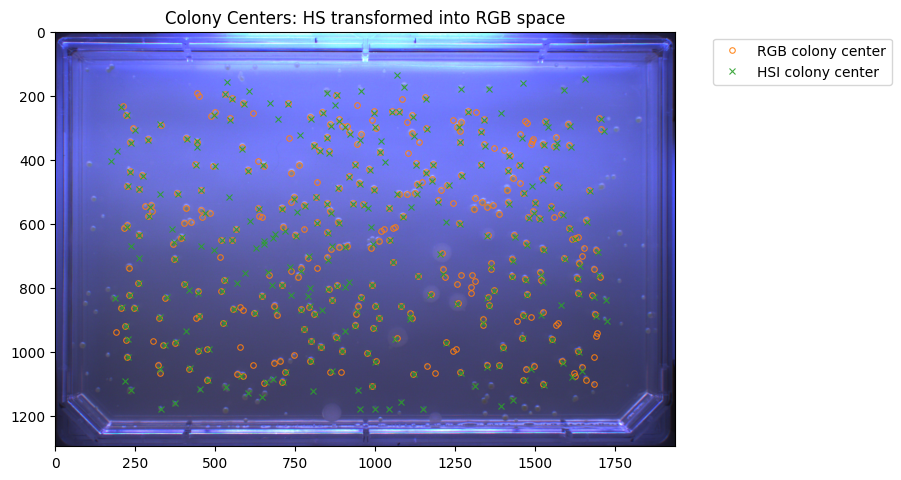

In [13]:
# Use the built-in plot method just like we did for anchors
fig, ax = plt.subplots(figsize=(8, 6))
aligner_colonies.plot("rgb", ["hsi"], ax=ax, plot_bg=True)
ax.set_title("Colony Centers: HS transformed into RGB space")
plt.show()